# 01. Análise exploratória e limpeza

**Objetivo:** conhecer os dados antes de usá-los e decidir o que entra na análise.

**Passos deste notebook:** (1) carregar o Excel, (2) olhar estrutura e qualidade, (3) limpar, (4) entender como os clientes compram, (5) salvar as compras limpas para o próximo notebook.

**Dados:** Online Retail II (UCI), transações de uma loja online do Reino Unido. Cada linha é um item de uma fatura.

## 1. Carregar os dados

O arquivo Excel tem duas abas. Usamos só a **primeira (dez/2009 a dez/2010)**: é simples e já cobre um ano. A segunda aba pode ser usada depois para testar o modelo em outro período.

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

raw_files = sorted(Path("../data/raw").glob("*.xlsx"))

if not raw_files:
    raise FileNotFoundError("No Excel file found in data/raw/.")

df = pd.read_excel(raw_files[0])

print(f"{df.shape[0]:,} rows and {df.shape[1]} columns")

df.head()

525,461 rows and 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 2. Estrutura e qualidade

Perguntas: tem valores ausentes? Linhas repetidas? Qual o período? Há valores estranhos em quantidade ou preço?

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[us]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 32.1+ MB


In [4]:
missing_summary = pd.DataFrame({'missing_summary': df.isna().sum(), '%': (df.isna().mean() * 100).round(2)})
display(missing_summary)
print('Linhas duplicadas:', df.duplicated().sum())
print('Período:', df['InvoiceDate'].min(), 'até', df['InvoiceDate'].max())

,missing_summary,%
Invoice,0,0.00
StockCode,0,0.00
Description,2928,0.56
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,107927,20.54
Country,0,0.00


Linhas duplicadas: 6865
Período: 2009-12-01 07:45:00 até 2010-12-09 20:01:00


**O que isso mostra:** a coluna `Customer ID` tem valores ausentes. Sem saber quem comprou, não dá para prever recompra, então essas linhas ficam de fora.

In [5]:
# Faturas que começam com 'C' são cancelamentos; quantidade negativa indica devolução
is_cancellation = df['Invoice'].astype(str).str.startswith('C')

data_issues = pd.DataFrame({
    'Check': [
        'Cancellation (prefix C)',
        'Negative quantity',
        'Zero price',
        'Negative price'
    ],
    'Rows': [
        is_cancellation.sum(),
        (df['Quantity'] < 0).sum(),
        (df['Price'] == 0).sum(),
        (df['Price'] < 0).sum()
    ],
})

data_issues['% of rows'] = (
    data_issues['Rows'] / len(df) * 100
).round(2)

data_issues

,Check,Rows,% of rows
0,Cancellation (prefix C),10206,1.94
1,Negative quantity,12326,2.35
2,Zero price,3687,0.70
3,Negative price,3,0.00


## 3. Limpeza

Regras para considerar uma linha uma **compra válida**:

- o cliente é conhecido (`Customer ID` preenchido);
- a fatura não é cancelamento;
- a quantidade é positiva;
- o preço é positivo (preço zero costuma ser ajuste ou brinde).

Também criamos `line_total` (quanto cada linha valeu) = quantidade x preço.

In [6]:
purchases = df[
    df['Customer ID'].notna()
    & ~df['Invoice'].astype(str).str.startswith('C')
    & (df['Quantity'] > 0)
    & (df['Price'] > 0)
].copy()

purchases['CustomerID'] = purchases['Customer ID'].astype(int)
purchases['Invoice'] = purchases['Invoice'].astype(str)
purchases['line_total'] = purchases['Quantity'] * purchases['Price']

print(f'Linhas antes: {len(df):,} | depois da limpeza: {len(purchases):,}')
print(f'Clientes: {purchases["CustomerID"].nunique():,}')

Linhas antes: 525,461 | depois da limpeza: 407,664
Clientes: 4,312


## 4. Como os clientes compram

**Frequência:** quantas faturas diferentes cada cliente tem. **Recência:** há quantos dias foi a última compra.

count    4312.0
mean        4.5
std         8.2
min         1.0
25%         1.0
50%         2.0
75%         5.0
max       205.0
Name: Invoice, dtype: float64

Clientes com apenas uma fatura: 32.9%


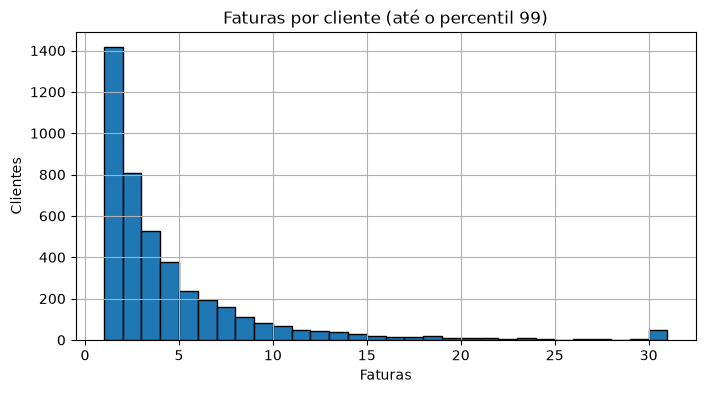

In [7]:
invoices_per_customer = purchases.groupby('CustomerID')['Invoice'].nunique()
print(invoices_per_customer.describe().round(1))
print(f'\nClientes com apenas uma fatura: {(invoices_per_customer == 1).mean():.1%}')

plt.figure(figsize=(8, 4))
invoices_per_customer.clip(upper=invoices_per_customer.quantile(0.99)).hist(bins=30, edgecolor='black')
plt.title('Faturas por cliente (até o percentil 99)')
plt.xlabel('Faturas')
plt.ylabel('Clientes')
plt.show()

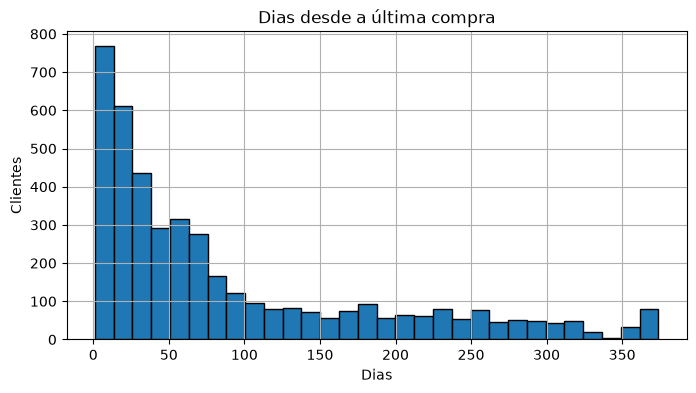

In [8]:
reference_date = purchases['InvoiceDate'].max() + pd.Timedelta(days=1)
recency = (reference_date - purchases.groupby('CustomerID')['InvoiceDate'].max()).dt.days

plt.figure(figsize=(8, 4))
recency.hist(bins=30, edgecolor='black')
plt.title('Dias desde a última compra')
plt.xlabel('Dias')
plt.ylabel('Clientes')
plt.show()

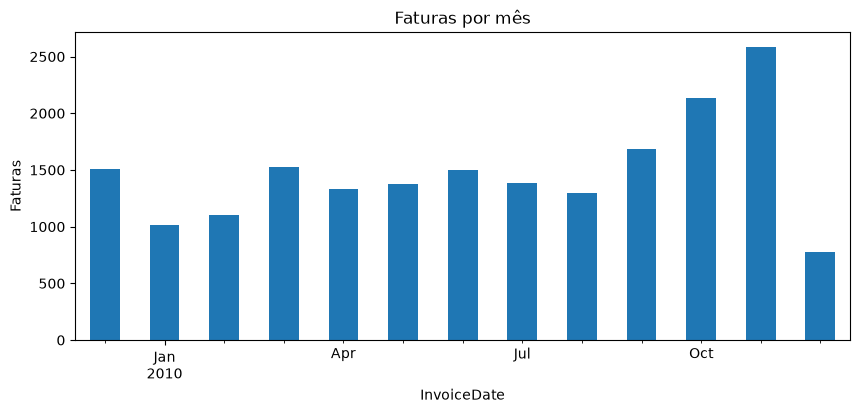

In [9]:
# Faturas por mês: mostra a sazonalidade da loja
invoices_by_month = purchases.groupby(purchases['InvoiceDate'].dt.to_period('M'))['Invoice'].nunique()
invoices_by_month.plot(kind='bar', figsize=(10, 4), title='Faturas por mês')
plt.ylabel('Faturas')
plt.show()

## 5. Salvar as compras limpas

O próximo notebook lê este arquivo, assim não precisamos reabrir o Excel (que é lento).

In [10]:
Path('../data/processed').mkdir(parents=True, exist_ok=True)
feature_columns = ['Invoice', 'StockCode', 'Quantity', 'InvoiceDate', 'Price', 'CustomerID', 'line_total']
purchases[feature_columns].to_csv('../data/processed/compras.csv', index=False)
print('Arquivo salvo em data/processed/compras.csv')

Arquivo salvo em data/processed/compras.csv


## Conclusões

- Após a limpeza, ficaram **407.664 linhas de compras e 4.312 clientes**. Foram removidas linhas sem identificação do cliente, cancelamentos, quantidades não positivas e preços não positivos.
- **32,9% dos clientes (1.419 de 4.312) fizeram apenas uma fatura** no período observado. Isso mostra que existe um grupo relevante sem recompra registrada, mas não significa necessariamente que nunca voltarão a comprar.
- Os meses com mais faturas foram **novembro de 2010 (2.587)** e **outubro de 2010 (2.133)**. A concentração de vendas no fim do período sugere sazonalidade, que pode afetar a previsão de recompra.
- Para prever recompra, é importante usar apenas informações disponíveis até uma data de corte e avaliar o modelo em um período posterior. A segunda aba do arquivo original poderia ajudar a testar a estabilidade em outro período.
- Limitação: clientes sem `Customer ID` não podem ser associados a um histórico individual e, por isso, foram excluídos da análise de recompra.